
GEOMETRY
Inner fuel radius: 0.0 m
Outer fuel radius: 0.00271 m
Inner cladding radius: 0.002826 m
Outer cladding radius: 0.003276 m
Gap thickness: 0.000116 m
Cladding thickness: 0.00045 m

SUBCHANNEL ANALYSIS
Triangular subchannel - pitch = 8.275 mm
Triangular subchannel - area = 12.793 mm^2
Triangular subchannel - D hyd = 4.972 mm

COOLANT PROPERTIES
Specific heat cp = 1267.71 J/kg K
Coolant temperature jump = 168.56 K


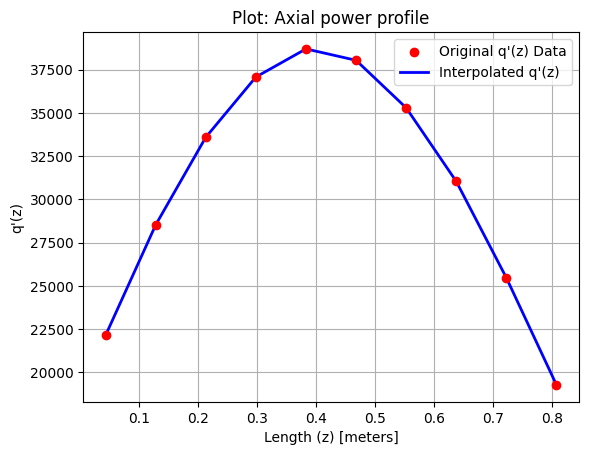

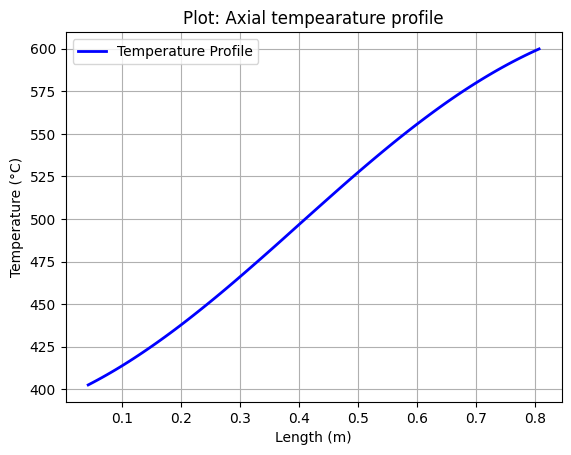

Coolant density = 834.41 kg/m3
Coolant velocity = 4.59 m/s
Coolant viscosity = 0.00023531991317261622 Pa s
Coolant Re = 80928.90
Coolant thermal conductivity = 67.86 W/mK
Coolant Pr = 0.004396135264386372
Coolant Pe = 355.77438192291737
Coolant heat transfer coefficient (h) = 123477.74870788913 W/m2 K

THERMAL ANALYSIS
T_clad_outer - T_coolant = 15.23 K
Cladding thermal conductivity = 19.69 W/mK
T_clad_inner - T_clad_outer = 49.92 K
T_clad_inner = 493.47 °C
Gap width = 0.00 K
Fuel outer temperature = 1107.50 °C
Fuel inner temperature = 2417.99 °C
Heat flux - fuel outer radius = 2.27 W/mm2
Fuel melting temperature at Pu = 0.27 wt./ and bu = 50.00 wt./ and = 2703.373 °C
Fuel melting temperature at Pu = 0.26 wt./ and bu = 100.00 wt./ and = 2695.446 °C

LARSON-MILLER - TIME TO RUPTURE, CLADDING

dopo 1 anno, slice 10, la piu calda
Cladding temperature = 900.000 K
Cladding Von Mises = 21.000 MPa
LMP = 21463.16
Rupture time = 603.18 y
thermal creep strain = 0.002936348072612483 %

dopo 1 ann

In [1]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

massFlowRate = 0.049    # in the triangular subchannel (kg/s)
T_cool_inlet = 668.15   # K

LHR = 38.7  # kW/m
LHR *= 1000 # -> W/m

r_fi = 0.0e-3   # Inner fuel radius (m)
r_fo = 2.71e-3  # Outer fuel radius (m)
r_ci = 2.826e-3 # Inner cladding radius (m)
r_co = 3.276e-3 # Outer cladding radius (m)

print(f"\nGEOMETRY")
print(f"Inner fuel radius: {r_fi} m")
print(f"Outer fuel radius: {r_fo} m")
print(f"Inner cladding radius: {r_ci} m")
print(f"Outer cladding radius: {r_co} m")
print(f"Gap thickness: {r_ci-r_fo:.3} m")
print(f"Cladding thickness: {r_co-r_ci:.4} m")

d = r_co * 2000 # Cladding outer diameter (mm)
pitch = 8.275   # pitch, center-to-center distance (mm)
A_pass = np.sqrt(3)/4*pitch**2 - np.pi * d**2 / 8 # triangular lattice (mm2)
P_wet = np.pi * d / 2 # wet perimeter (mm)
D_hyd = 4 * A_pass / P_wet  # mm

f = 1/2 # number of rods per channel

print(f"\nSUBCHANNEL ANALYSIS")
print(f"Triangular subchannel - pitch = {pitch:.5} mm")
print(f"Triangular subchannel - area = {A_pass:.5} mm^2")
print(f"Triangular subchannel - D hyd = {D_hyd:.5} mm")

activeLength = 0.85 # (m)
gapVolume = (r_ci**2 - r_fo**2)*np.pi*activeLength
gasPressure = 1e5 # filling gas pressure (Pa)
gasTemperature = 293.15 # filling gas temperature (K)
lowerPlenumVolume = 19500 # (mm3)
upperPlenumLength = 77.1e-3 # (m)
upperPlenumVolume = np.pi * r_ci**2 * upperPlenumLength
volumeFractionInUpperPlenum = 0.9
upperPlenumVolume = volumeFractionInUpperPlenum * upperPlenumVolume # (m3)

oxygenToMetalRatio = 1.957

powerDensity = LHR / (np.pi * (r_fo**2 - r_fi**2))  # power density or volumetric heat generation rate (W/m3)
fissionRate = powerDensity / (3e-11)                # fission rate density (fiss/m3 s)

# THERMAL ANALYSIS: COOLANT

T_cool = T_cool_inlet
def specificHeat(T):
    return 1608 - 0.7481 * T + 3.929*1e-4 * T**2 # Specific heat capacity (J/kg*K)
cp = specificHeat(T_cool)
dT_coolant = LHR / (massFlowRate * cp) * 2 * activeLength * f / np.pi
T_cool = T_cool + dT_coolant/2 # average coolant temperature
cp = specificHeat(T_cool) # average specific heat
dT_coolant = LHR / (massFlowRate * cp) * 2 * activeLength * f / np.pi

print("\nCOOLANT PROPERTIES")
print(f"Specific heat cp = {cp:.2f} J/kg K")
print(f"Coolant temperature jump = {dT_coolant:.2f} K")

z_data = np.array([42.5, 127.5, 212.5, 297.5, 382.5, 467.5, 552.5, 637.5, 722.5, 807.5]) * 1e-3 # (m)
powerProfile_data = np.array([0.572, 0.737, 0.868, 0.958, 1.000, 0.983, 0.912, 0.802, 0.658, 0.498]) * LHR

def powerProfile(z):
    return np.interp(z, z_data, powerProfile_data)

def trapezoidal_rule(f, a, b, N):
    h = (b - a) / N
    x = np.linspace(a, b, N+1)
    y = f(x)

    integral = h * (0.5 * y[0] + np.sum(y[1:-1]) + 0.5 * y[-1])
    return integral

def T(z, N=1000):
    integral = trapezoidal_rule(powerProfile, 0, z, N)
    return T_cool_inlet + (f / (massFlowRate * cp)) * integral

z_values = np.linspace(z_data[0], z_data[-1], 100)
power_interp_values = powerProfile(z_values)

T_values = [T(z) for z in z_values]

# Plot: Axial power profile
plt.scatter(z_data, powerProfile_data, color="red", label="Original q'(z) Data", zorder=5)
plt.plot(z_values, power_interp_values, label="Interpolated q'(z)", color="blue", lw=2)
plt.xlabel("Length (z) [meters]")
plt.ylabel("q'(z)")
plt.title("Plot: Axial power profile")
plt.grid(True)
plt.legend()
plt.show()

# Plot: Axial tempearature profile
plt.plot(z_values, np.array(T_values)-273.15, label="Temperature Profile", color="blue", lw=2)
plt.xlabel("Length (m)")
plt.ylabel("Temperature (°C)")
plt.title("Plot: Axial tempearature profile")
plt.grid(True)
plt.legend()

ax = plt.gca()
ax.xaxis.set_major_formatter(mticker.ScalarFormatter(useOffset=False))
ax.yaxis.set_major_formatter(mticker.ScalarFormatter(useOffset=False))
ax.ticklabel_format(style='plain', axis='both')

plt.show()

# Sodium Coolant Density (kg/m³)
# T in Kelvin
# Miller,1954
def coolantDensity(T):
    return 1020 - 0.247 * T

rho_cool = coolantDensity(T_cool)
print(f"Coolant density = {rho_cool:.2f} kg/m3")

A_pass = A_pass * 1e-6
v_cool = massFlowRate / (rho_cool * A_pass)
print(f"Coolant velocity = {v_cool:.2f} m/s") # TRANSURANUS: coolant velocity 5.1-5.4 m/s

# Reynolds
# Dynamic viscosity (Pa·s)
def coolant_dynamic_viscosity(T):
    return 1e-3 * np.exp(813.9/T - 2.53)

visc_cool = coolant_dynamic_viscosity(T_cool)
print(f"Coolant viscosity = {coolant_dynamic_viscosity(T_cool)} Pa s")

D_hyd = D_hyd/1000 # (m)
Re = rho_cool * v_cool * D_hyd / coolant_dynamic_viscosity(T_cool)

print(f"Coolant Re = {Re:.2f}")

# Thermal conductivity (W/mK)
def coolant_thermal_conductivity(T):
    return 110 - 0.0648 * T + 1.16 * 1e-5 * T**2

k_cool = coolant_thermal_conductivity(T_cool)
print(f"Coolant thermal conductivity = {k_cool:.2f} W/mK")

Pr = cp * visc_cool / k_cool
print(f"Coolant Pr = {Pr}")

Pe = Re * Pr
print(f"Coolant Pe = {Pe}")

# Lyon-Martinelli
Nu = 6.3+0.025*Pe**0.8
coolant_HTC = Nu * k_cool / D_hyd 
print(f"Coolant heat transfer coefficient (h) = {coolant_HTC} W/m2 K")

print("\nTHERMAL ANALYSIS")

# RADIAL HEAT TRANSFER - THERMAL RESISTANCE
R_cool = 1 / (2 * np.pi * r_co * coolant_HTC)
dT_cool_clad = LHR * R_cool
print(f"T_clad_outer - T_coolant = {dT_cool_clad:.2f} K")
T_clad = T_cool + dT_cool_clad

t_clad = 0.451e-3 # (m)

# Cladding thermal conductivity (W/mK)
k_clad = 13.95+0.01163*(T_clad-273.15)
print(f"Cladding thermal conductivity = {k_clad:2.2f} W/mK")

R_clad = t_clad / (2 * np.pi * r_ci * k_clad)
dT_clad = LHR * R_clad
print(f"T_clad_inner - T_clad_outer = {dT_clad:.2f} K")

print(f"T_clad_inner = {T_clad-273.15:.2f} °C")

gap_width = r_ci - r_fo

print(f"Gap width = {gap_width:.2f} K")

k_gap = 15.8 * 10**(-4) * T_clad**0.79

h_gap = k_gap / gap_width
dT_gap = LHR / (2 * np.pi * r_fo * h_gap)
k_gap = 15.8 * 10**(-4) * (T_clad + dT_gap/2)**0.79
h_gap = k_gap / gap_width

T_fo = T_clad + LHR / (2 * np.pi * r_fo * h_gap)

print(f"Fuel outer temperature = {T_fo - 273.15:.2f} °C")

k_f = 2.35 # W/mK

T_fi = T_fo + LHR / (4 * np.pi * k_f)

print(f"Fuel inner temperature = {T_fi - 273.15:.2f} °C")

heat_flux = LHR / (2 * np.pi * r_fo)

print(f"Heat flux - fuel outer radius = {heat_flux/1000000:.2f} W/mm2")

x = 2 - 1.957

Pu = 0.27
bu = 50
T_melting = 2964.92 + (3147 - 364.85 * Pu - 1014.15 * x - 2964.92) * np.exp(-bu / 40.43)
print(f"Fuel melting temperature at Pu = {Pu:2.2f} wt./ and bu = {bu:2.2f} wt./ and = {T_melting - 273.15:3.3f} °C")

Pu = 0.26
bu = 100
T_melting = 2964.92 + (3147 - 364.85 * Pu - 1014.15 * x - 2964.92) * np.exp(-bu / 40.43)
print(f"Fuel melting temperature at Pu = {Pu:2.2f} wt./ and bu = {bu:2.2f} wt./ and = {T_melting - 273.15:3.3f} °C")


# LARSON-MILLER
print("\nLARSON-MILLER - TIME TO RUPTURE, CLADDING")

print("\ndopo 1 anno, slice 10, la piu calda")
T_clad = 900
sigma_eq = 21 # MPa
LMP = (2060 - sigma_eq)/0.095
t_rupture = 10**(LMP / T_clad - 17.125)
print(f"Cladding temperature = {T_clad:3.3f} K")
print(f"Cladding Von Mises = {sigma_eq:3.3f} MPa")
print(f"LMP = {LMP:2.2f}")
print(f"Rupture time = {t_rupture/8760:2.2f} y")
eps_th_rate = 2.3 * 10**14 * np.exp((-84600)/(1.986 * T_clad)) * np.sinh((34.54 * sigma_eq)/(0.8075 * 1.986 * T_clad))
print(f"thermal creep strain = {eps_th_rate * 8760} %")

print("\ndopo 1 anno, slice 6, la piu carica")
T_clad = 823
sigma_eq = 152 # MPa
LMP = (2060 - sigma_eq)/0.095
t_rupture = 10**(LMP / T_clad - 17.125)
print(f"Cladding temperature = {T_clad:3.3f} K")
print(f"Cladding Von Mises = {sigma_eq:3.3f} MPa")
print(f"LMP = {LMP:2.2f}")
print(f"Rupture time = {t_rupture/8760:2.2f} y")
eps_th_rate = 2.3 * 10**14 * np.exp((-84600)/(1.986 * T_clad)) * np.sinh((34.54 * sigma_eq)/(0.8075 * 1.986 * T_clad))
print(f"thermal creep strain = {eps_th_rate * 8760} %")

# dopo 2 anni, slice 5
print("\ndopo 2 anni, slice 5, la più carica")
T_clad = 550+273
sigma_eq = 290 # MPa
LMP = (2060 - sigma_eq)/0.095
t_rupture = 10**(LMP / T_clad - 17.125)
print(f"Cladding temperature = {T_clad:3.3f} K")
print(f"Cladding Von Mises = {sigma_eq:3.3f} MPa")
print(f"LMP = {LMP:2.2f}")
print(f"Rupture time = {t_rupture/8760:2.2f} y")
eps_th_rate = 2.3 * 10**14 * np.exp((-84600)/(1.986 * T_clad)) * np.sinh((34.54 * sigma_eq)/(0.8075 * 1.986 * T_clad))
print(f"thermal creep strain = {eps_th_rate * 16000} %")

# dopo 2 anni, slice 10
print("\ndopo 2 anni, slice 10, la piu calda")
T_clad = 900
sigma_eq = 142 # MPa
LMP = (2060 - sigma_eq)/0.095
t_rupture = 10**(LMP / T_clad - 17.125)
print(f"Cladding temperature = {T_clad:3.3f} K")
print(f"Cladding Von Mises = {sigma_eq:3.3f} MPa")
print(f"LMP = {LMP:2.2f}")
print(f"Rupture time = {t_rupture/8760:2.2f} y")
eps_th_rate = 2.3 * 10**14 * np.exp((-84600)/(1.986 * T_clad)) * np.sinh((34.54 * sigma_eq)/(0.8075 * 1.986 * T_clad))
print(f"thermal creep strain = {eps_th_rate * 16000} %")


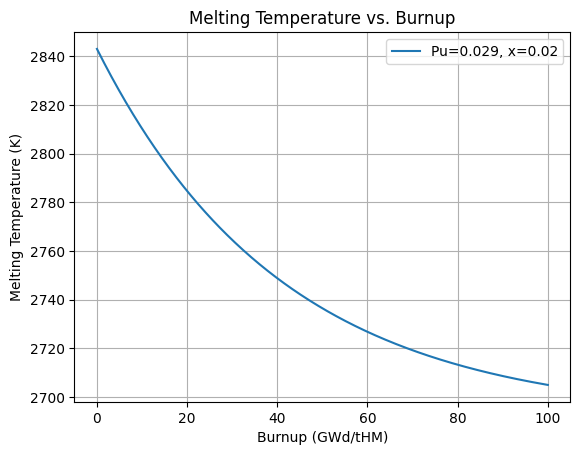

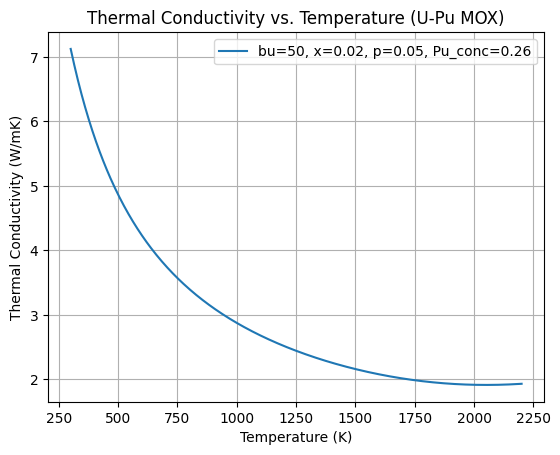

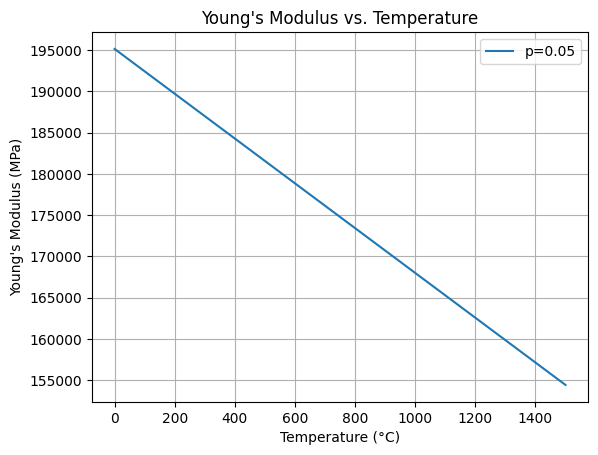

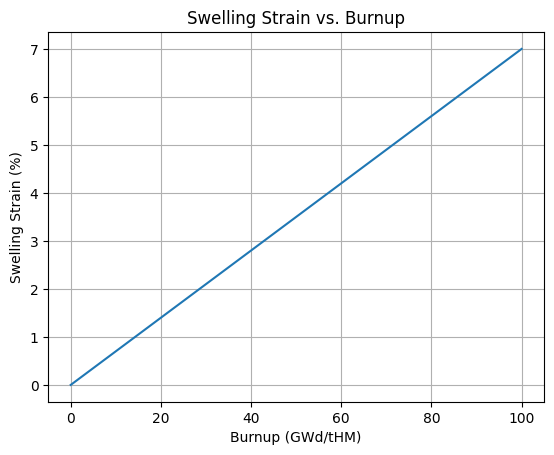

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Fuel properties correlations

def melting_temperature(bu, Pu, x):
    T_m = 2964.92 + (3147 - 364.85 * Pu - 1014.15 * x - 2964.92) * np.exp(-bu / 41.01)
    return T_m

def thermal_conductivity_mox(T, p, x, Pu_conc, beta):
    """
    Calculate the thermal conductivity of MOX fuel.
    
    Parameters:
    T (float): Temperature in Kelvin.
    p (float): Porosity (fraction).
    x (float): Deviation from stoichiometry.
    Pu_conc (float): Plutonium concentration in wt.%.
    beta (float): Burnup in GWd/t_HM.
    
    Returns:
    float: Thermal conductivity in W/(m·K).
    """
    D = 5.27e9
    E = 17109.5
    A = 0.01926 + 1.06e-6 * x + 2.63e-8 * Pu_conc
    B = 2.39e-4 + 1.37e-13 * Pu_conc
    k_0 = (1 / (A + B * T) + D / T**2 * np.exp(-E / T)) * (1 - p)**2.5
    k = 1.755 + (k_0 - 1.755) * np.exp(-beta / 128.75)
    
    return k

def linear_thermal_expansion_coefficient():
    # Reference temperature: 25°C
    αL = 1.2e-5
    return αL

def youngs_modulus_mox(T_C, p):
    # Young’s modulus (MPa)
    # T in [°C], p is porosity
    E = (22.43 * 10**4 - 31.19 * T_C) * (1 - 2.6 * p)
    return E

def poisson_coefficient():
    ν = 0.32
    return ν

def swelling_strain(bu):
    # Swelling strain (%) (bu in [GWd/tHM])
    ε_swe_tot = 0.07 * bu
    return ε_swe_tot

# Plotting functions
def plot_melting_temperature():
    bu_values = np.linspace(0, 100, 500)
    Pu = 0.029  # Example value for Pu content
    x = 0.02  # Example value for stoichiometric deviation
    T_m_values = melting_temperature(bu_values, Pu, x) - 273.15

    plt.figure()
    plt.plot(bu_values, T_m_values, label=f'Pu={Pu}, x={x}')
    plt.xlabel('Burnup (GWd/tHM)')
    plt.ylabel('Melting Temperature (K)')
    plt.title('Melting Temperature vs. Burnup')
    plt.legend()
    plt.grid(True)
    plt.show()

def plot_thermal_conductivity_mox():
    T_values = np.linspace(300, 2200, 500)
    bu = 50    # Example value for burnup
    x = 0.02   # Example value for stoichiometric deviation
    p = 0.05   # Example value for porosity
    Pu_conc = 0.26
    λ_values = thermal_conductivity_mox(T_values, p, x, Pu_conc, bu)

    plt.figure()
    plt.plot(T_values, λ_values, label=f'bu={bu}, x={x}, p={p}, Pu_conc={Pu_conc}')
    plt.xlabel('Temperature (K)')
    plt.ylabel('Thermal Conductivity (W/mK)')
    plt.title('Thermal Conductivity vs. Temperature (U-Pu MOX)')
    plt.legend()
    plt.grid(True)
    plt.show()

def plot_youngs_modulus_mox():
    T_values = np.linspace(0, 1500, 500)
    p = 0.05  # Example value for porosity
    E_values = youngs_modulus_mox(T_values, p)

    plt.figure()
    plt.plot(T_values, E_values, label=f'p={p}')
    plt.xlabel('Temperature (°C)')
    plt.ylabel('Young\'s Modulus (MPa)')
    plt.title('Young\'s Modulus vs. Temperature')
    plt.legend()
    plt.grid(True)
    plt.show()

def plot_swelling_strain():
    bu_values = np.linspace(0, 100, 500)
    ε_swe_tot_values = swelling_strain(bu_values)

    plt.figure()
    plt.plot(bu_values, ε_swe_tot_values)
    plt.xlabel('Burnup (GWd/tHM)')
    plt.ylabel('Swelling Strain (%)')
    plt.title('Swelling Strain vs. Burnup')
    plt.grid(True)
    plt.show()

# Call plotting functions
plot_melting_temperature()
plot_thermal_conductivity_mox()
plot_youngs_modulus_mox()
plot_swelling_strain()

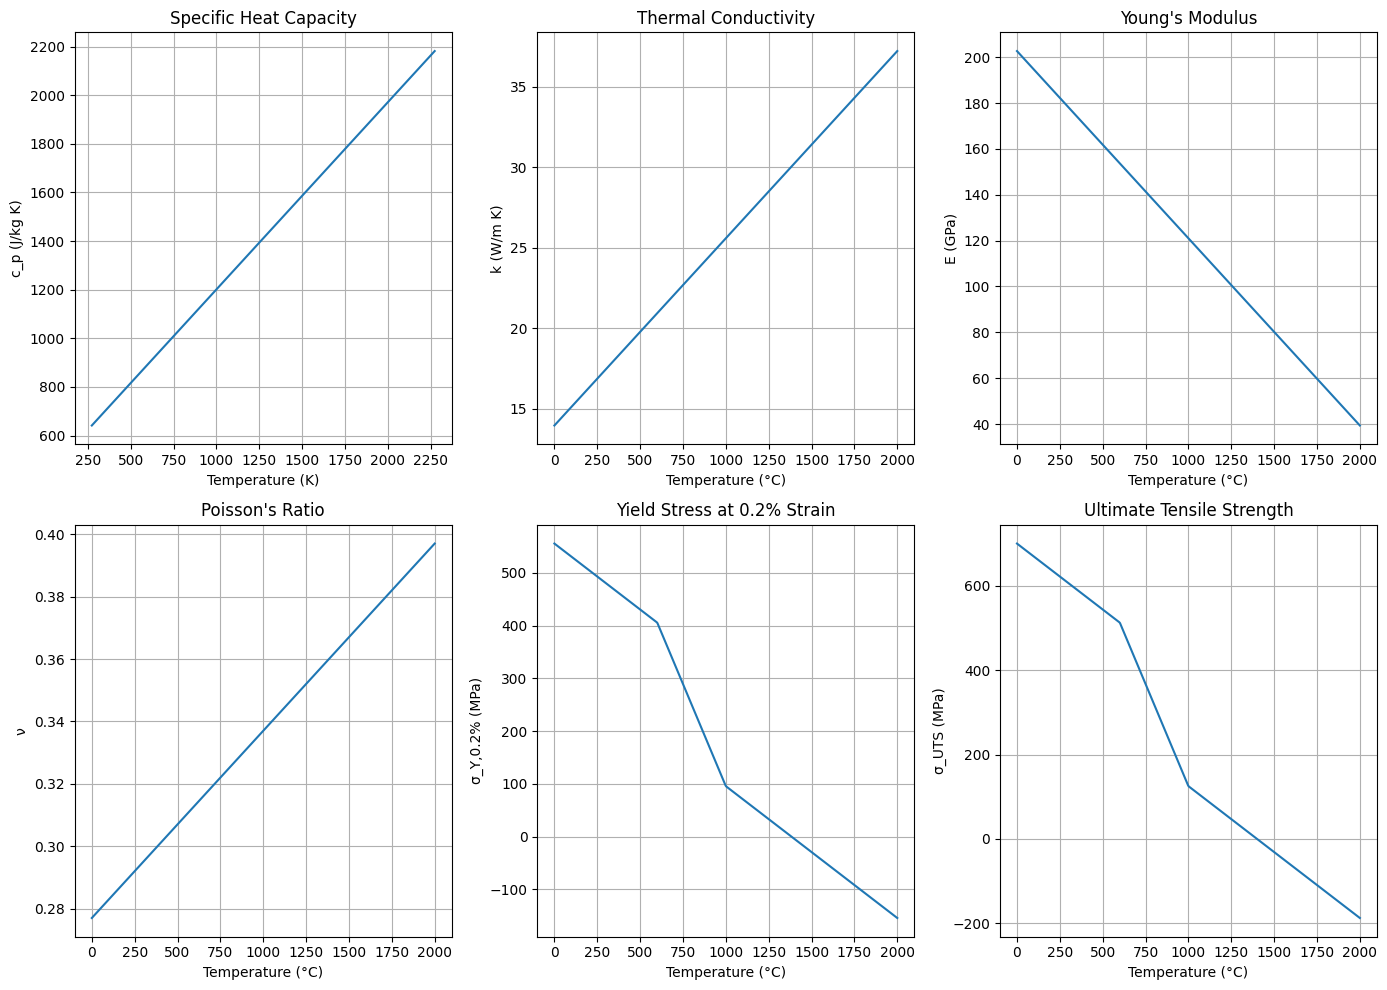

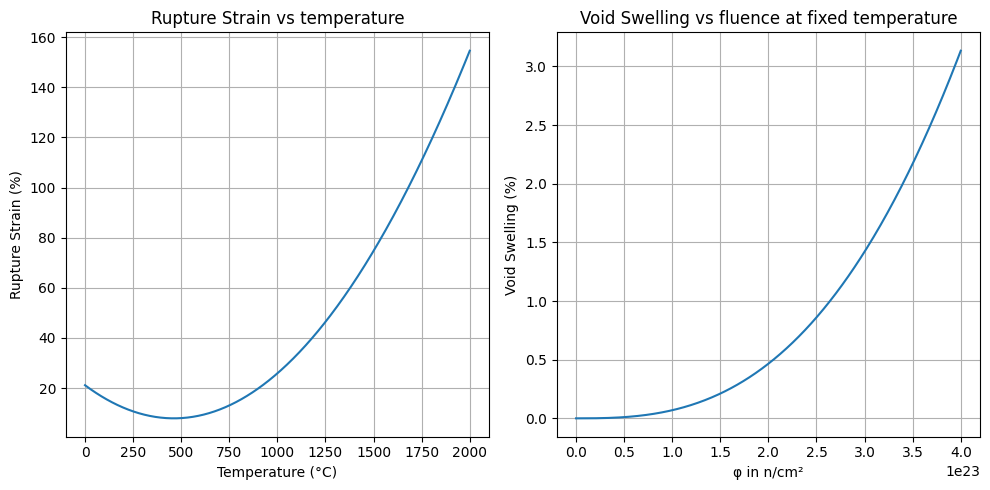

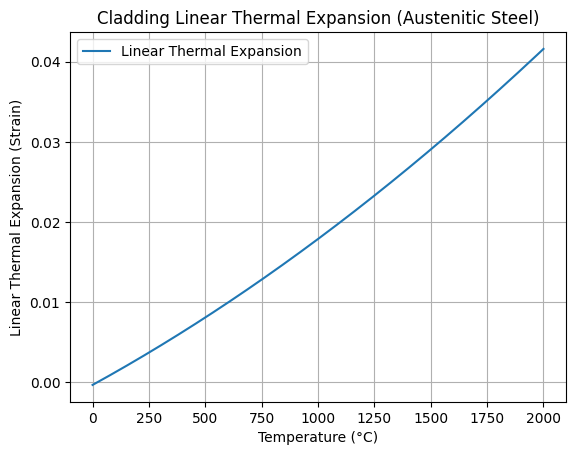

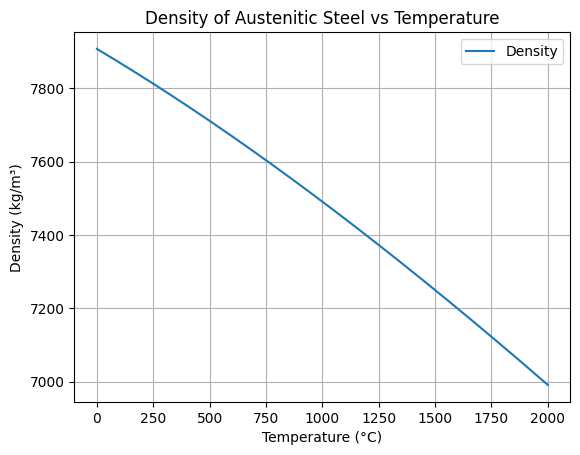

In [ ]:
# CLADDING PROPERTIES

def linear_thermal_expansion(T_C):
    """
    Calculate the linear thermal expansion of austenitic steel.
    
    Parameters:
    T_C (float): Temperature in Celsius.
    
    Returns:
    float: Linear thermal expansion (fractional increase).
    """
    # Linear thermal expansion formula for austenitic steel
    epsilon_th = -3.101e-4 + 1.545e-5 * T_C + 2.75e-9 * T_C**2
    return epsilon_th

def density(T_C):
    """
    Calculate the density of austenitic steel based on thermal expansion.
    
    Parameters:
    T_C (float): Temperature in Celsius.
    
    Returns:
    float: Density in kg/m^3.
    """
    epsilon_th = linear_thermal_expansion(T_C)
    rho = 7900 * (1 + epsilon_th)**(-3)
    return rho

def specific_heat(T_K):
    return 431 + 0.77 * T_K + 8.72e-5 / T_K**2

# 2. Thermal Conductivity
def thermal_conductivity(T_C):
    return 13.95 + 0.01163 * T_C

# 3. Young’s Modulus
def youngs_modulus_cladding(T_C):
    return 202.7 - 0.08167 * T_C

# 4. Poisson’s Ratio
def poissons_ratio(T_C):
    return 0.277 + 6e-5 * T_C

# 5. Yield Stress at 0.2% Strain
def yield_stress(T_C):
    if T_C < 600:
        return 555.5 - 0.25 * T_C
    elif 600 <= T_C < 1000:
        return 405.5 - 0.775 * (T_C - 600)
    else:
        return 345.5 - 0.25 * T_C

# 6. Ultimate Tensile Strength
def ultimate_tensile_strength(T_C):
    if T_C < 600:
        return 700 - 0.3125 * T_C
    elif 600 <= T_C < 1000:
        return 512.5 - 0.969 * (T_C - 600)
    else:
        return 437.5 - 0.3125 * T_C

# 7. Rupture Strain
def rupture_strain(T_C):
    return 8 + 4.74e-3 * (T_C - 500) + 6.2e-5 * (T_C - 500)**2

# 8. Void Swelling (%)
def void_swelling(T_C, phi):
    return 1.5e-3 * np.exp(-2.5 * ((T_C - 450) / 100)**2) * (phi / 1e22)**2.75

# Plotting cladding properties
def plot_cladding_properties():
    T_C = np.linspace(0, 2000, 500)  # Temperature in Celsius
    T_K = T_C + 273.15  # Convert to Kelvin for specific heat
    phi = np.linspace(1,4e23,500) #3.5e23 fluenza dopo due anni nelle slice 5-6

    plt.figure(figsize=(14, 10))

    # Plot specific heat
    plt.subplot(2, 3, 1)
    plt.plot(T_K, specific_heat(T_K), label='Specific Heat (c_p)')
    plt.xlabel('Temperature (K)')
    plt.ylabel('c_p (J/kg K)')
    plt.title('Specific Heat Capacity')
    plt.grid(True)

    # Plot thermal conductivity
    plt.subplot(2, 3, 2)
    plt.plot(T_C, thermal_conductivity(T_C), label='Thermal Conductivity')
    plt.xlabel('Temperature (°C)')
    plt.ylabel('k (W/m K)')
    plt.title('Thermal Conductivity')
    plt.grid(True)

    # Plot Young's Modulus
    plt.subplot(2, 3, 3)
    plt.plot(T_C, youngs_modulus_cladding(T_C), label='Young\'s Modulus')
    plt.xlabel('Temperature (°C)')
    plt.ylabel('E (GPa)')
    plt.title('Young\'s Modulus')
    plt.grid(True)

    # Plot Poisson's Ratio
    plt.subplot(2, 3, 4)
    plt.plot(T_C, poissons_ratio(T_C), label='Poisson\'s Ratio')
    plt.xlabel('Temperature (°C)')
    plt.ylabel('ν')
    plt.title('Poisson\'s Ratio')
    plt.grid(True)

    # Plot Yield Stress
    plt.subplot(2, 3, 5)
    plt.plot(T_C, [yield_stress(T) for T in T_C], label='Yield Stress (σ_Y,0.2%)')
    plt.xlabel('Temperature (°C)')
    plt.ylabel('σ_Y,0.2% (MPa)')
    plt.title('Yield Stress at 0.2% Strain')
    plt.grid(True)

    # Plot Ultimate Tensile Strength (UTS)
    plt.subplot(2, 3, 6)
    plt.plot(T_C, [ultimate_tensile_strength(T) for T in T_C], label='Ultimate Tensile Strength (σ_UTS)')
    plt.xlabel('Temperature (°C)')
    plt.ylabel('σ_UTS (MPa)')
    plt.title('Ultimate Tensile Strength')
    plt.grid(True)
    plt.tight_layout()
    plt.show()
    plt.figure(figsize=(10, 5))

    # Plot rupture strain
    plt.subplot(1, 2, 1)
    plt.plot(T_C, rupture_strain(T_C), label='Rupture Strain')
    plt.xlabel('Temperature (°C)')
    plt.ylabel('Rupture Strain (%)')
    plt.title('Rupture Strain vs temperature')
    plt.grid(True)

    # Plot void swelling
    plt.subplot(1, 2, 2)
    plt.plot(phi, void_swelling(550, phi), label=f'Void Swelling (φ in n/cm²)')
    plt.xlabel('φ in n/cm²')
    plt.ylabel('Void Swelling (%)')
    plt.title('Void Swelling vs fluence at fixed temperature')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # Plot linear thermal expansion
    plt.figure()
    plt.plot(T_C, linear_thermal_expansion(T_C), label='Linear Thermal Expansion')
    plt.xlabel('Temperature (°C)')
    plt.ylabel('Linear Thermal Expansion (Strain)')
    plt.title('Cladding Linear Thermal Expansion (Austenitic Steel)')
    plt.legend()
    plt.grid(True)
    plt.show()
    
    # Plot density
    plt.figure()
    plt.plot(T_C, density(T_C), label='Density')
    plt.xlabel('Temperature (°C)')
    plt.ylabel('Density (kg/m³)')
    plt.title('Density of Austenitic Steel vs Temperature')
    plt.legend()
    plt.grid(True)
    plt.show()


plot_cladding_properties()


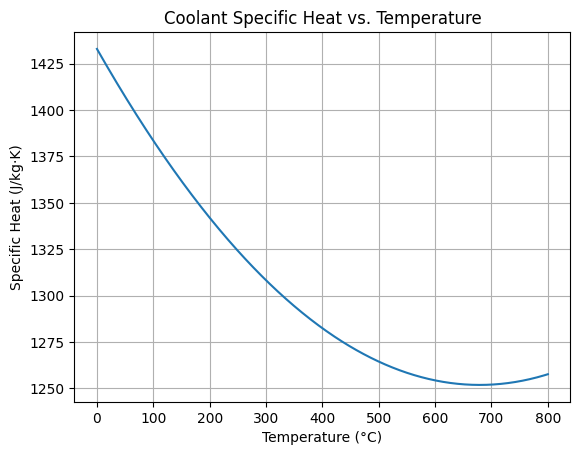

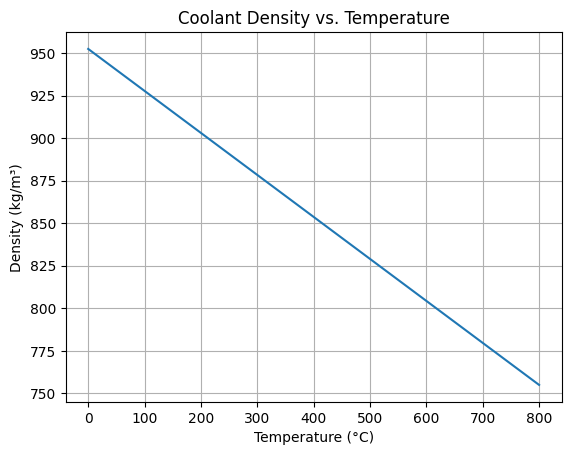

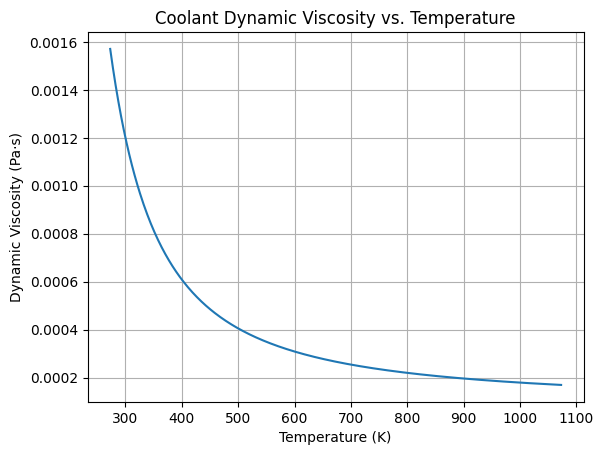

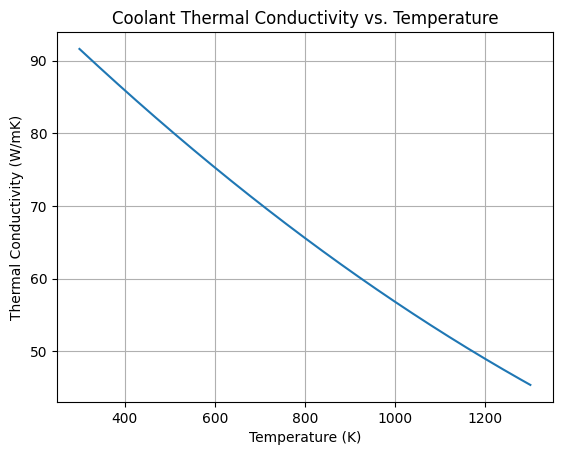

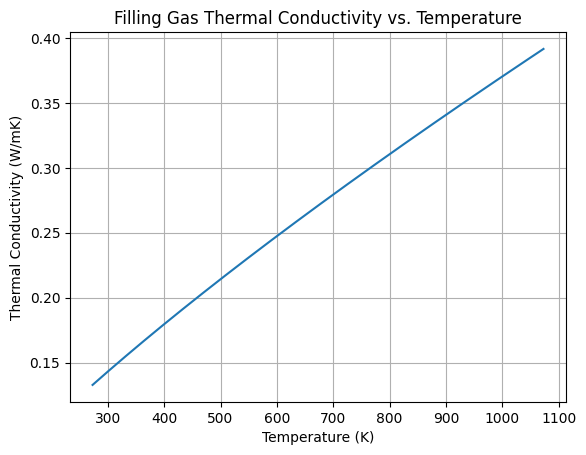

In [4]:

# Coolant properties correlations

# 1. Melting temperature (°C) at atmospheric pressure
def coolant_melting_temperature():
    Tm = 98  # Constant value
    return Tm

# 2. Boiling temperature (°C) at atmospheric pressure
def coolant_boiling_temperature():
    Tb = 882  # Constant value
    return Tb

# Isobaric specific heat (J/kg·K)
# Bogoslovskaya, 2002
def coolant_specific_heat(T):
    cp = 1608 - 0.7481 * T + 3.929e-4 * T**2
    return cp

# Sodium Coolant Density (kg/m³)
# T in Kelvin
# Miller,1954
def coolant_density(T):
    ρNa = 1020 - 0.247 * T
    return ρNa

# 5. Dynamic viscosity (Pa·s)
def coolant_dynamic_viscosity(T):
    # η = np.exp(556.835/T - 0.3958 * np.log(T) - 6.4406)
    # η = 1e-3 * np.exp(2.3 * (0.5108 + 220.65 / T - 0.2139 * np.log(T)))
    η = 1e-3 * np.exp(813.9/T - 2.53)
    return η

# 6. Thermal conductivity (W/mK)
def coolant_thermal_conductivity(T):
    # T_F = T * 9/5 + 32  # Convert °C to °F
    # λ = 94 - 3.25e-2 * T_F + 3.62e-6 * T_F**2
    # λ = 120.9 - 0.096 * T + 2.923 * 1e-5 * T**2
    λ = 110 - 0.0648 * T + 1.16 * 1e-5 * T**2
    return λ

# 7. Nusselt number (-)
# Pe is the Péclet number, a required input parameter
def coolant_nusselt_number(Pe):
    Nu = 7 + 0.025 * Pe**0.8
    return Nu

# 8. Filling gas Thermal conductivity (W/mK)
def gas_thermal_conductivity(T):
    λHe = 15.8e-4 * T**0.79
    return λHe

# Plotting functions for coolant properties
def plot_coolant_specific_heat():
    T_values = np.linspace(0, 800, 500)
    cp_values = coolant_specific_heat(T_values + 273.15)

    plt.figure()
    plt.plot(T_values, cp_values)
    plt.xlabel('Temperature (°C)')
    plt.ylabel('Specific Heat (J/kg·K)')
    plt.title('Coolant Specific Heat vs. Temperature')
    plt.grid(True)
    plt.show()

def plot_coolant_density():
    T_values = np.linspace(0, 800, 500) # T in Celsius
    ρ_values = coolant_density(T_values+273.15) # Convert to Kelvin

    plt.figure()
    plt.plot(T_values, ρ_values)
    plt.xlabel('Temperature (°C)')
    plt.ylabel('Density (kg/m³)')
    plt.title('Coolant Density vs. Temperature')
    plt.grid(True)
    plt.show()

def plot_coolant_dynamic_viscosity():
    T_values = np.linspace(273, 1073, 500)  # Temperature in Kelvin
    η_values = coolant_dynamic_viscosity(T_values)

    plt.figure()
    plt.plot(T_values, η_values)
    plt.xlabel('Temperature (K)')
    plt.ylabel('Dynamic Viscosity (Pa·s)')
    plt.title('Coolant Dynamic Viscosity vs. Temperature')
    plt.grid(True)
    plt.show()

def plot_coolant_thermal_conductivity():
    T_values = np.linspace(300, 1300, 500)
    λ_values = coolant_thermal_conductivity(T_values)

    plt.figure()
    plt.plot(T_values, λ_values)
    plt.xlabel('Temperature (K)')
    plt.ylabel('Thermal Conductivity (W/mK)')
    plt.title('Coolant Thermal Conductivity vs. Temperature')
    plt.grid(True)
    plt.show()

def plot_gas_thermal_conductivity():
    T_values = np.linspace(273, 1073, 500)  # Temperature in Kelvin
    λHe_values = gas_thermal_conductivity(T_values)

    plt.figure()
    plt.plot(T_values, λHe_values)
    plt.xlabel('Temperature (K)')
    plt.ylabel('Thermal Conductivity (W/mK)')
    plt.title('Filling Gas Thermal Conductivity vs. Temperature')
    plt.grid(True)
    plt.show()

# Call plotting functions for coolant properties
plot_coolant_specific_heat()
plot_coolant_density()
plot_coolant_dynamic_viscosity()
plot_coolant_thermal_conductivity()
plot_gas_thermal_conductivity()

In [5]:
import numpy as np

class fuel_rod():
    def __init__(self):
        pass

    def setPower(self, LHR):
        self.LHR = LHR
        self.heat_flux_co = self.LHR / (np.pi * self.D_co)

    def setFuelProperties(self, fabrication_porosity):
        self.fabrication_porosity = fabrication_porosity
        self.fabrication_density = 10960 * (1.0 - self.fabrication_porosity)
    
    def setCladdingGeometry(self, inner_diameter, outer_diameter):
        self.D_ci = inner_diameter
        self.D_co = outer_diameter

    def bundle(self, pitch, array, flow_rate):
        self.pitch = pitch
        self.bundle_type = array

        self.coolant_area = self.pitch**2 - np.pi * self.D_co**2 / 4
        self.wetted_perimeter = np.pi * self.D_co
        self.hydraulic_diameter = 4 * self.coolant_area / self.wetted_perimeter

        self.flow_rate = flow_rate
        self.coolant_mass_flux = self.flow_rate / self.coolant_area

    def getInfo(self):
        
        print(f"Cladding inner diameter = {self.D_ci*1000:1.2f} mm")
        print(f"Cladding outer diameter = {self.D_co*1000:1.2f} mm")

        print(f"Fuel initial porosity = {self.fabrication_porosity*100:1.2f} %")
        print(f"Fuel initial density = {self.fabrication_density:1.2f} kg/m3")
        
        print(f"Pitch = {self.pitch*1000:1.2f} mm")

        print(f"Hydraulic diameter = {self.hydraulic_diameter*1000:1.2f} mm")
        print(f"Coolant area = {self.coolant_area*1000000:1.2f} mm2")
        print(f"Coolant flux = {self.coolant_mass_flux:1.2f} kg / m2 s")

        print(f"Bundle type: {self.bundle_type} array")

        print(f"Heat flux (at outer cladding): {self.heat_flux_co/10000:1.2f} W/cm2")

In [6]:
pitch = 12.6e-3

D_co = 4.75e-3 * 2
D_ci = 4.18e-3 * 2

linear_heat_rate = 20e3
# coolant_kinematic_viscosity = # m2 / s
# coolant_velocity = 

flow_rate = 1.2226545e6 # g/h

regate = fuel_rod()
regate.setCladdingGeometry(inner_diameter=D_ci, outer_diameter=D_co)
regate.setFuelProperties(fabrication_porosity=0.05246)
regate.bundle(pitch=pitch, array="square", flow_rate = flow_rate * 0.001 / 3600)
regate.setPower(LHR=linear_heat_rate)

regate.getInfo()





Cladding inner diameter = 8.36 mm
Cladding outer diameter = 9.50 mm
Fuel initial porosity = 5.25 %
Fuel initial density = 10385.04 kg/m3
Pitch = 12.60 mm
Hydraulic diameter = 11.78 mm
Coolant area = 87.88 mm2
Coolant flux = 3864.76 kg / m2 s
Bundle type: square array
Heat flux (at outer cladding): 67.01 W/cm2


In [7]:
def epsilon_th(T):
    """
    Calculate the thermal strain (εth) as a function of temperature T in °C.
    
    Parameters:
    T (float): Temperature in °C.
    
    Returns:
    float: The calculated thermal strain (εth).
    """
    return -3.101e-4 + 1.545e-5 * T + 2.75e-9 * T**2

# cladding outer
T = 567  # Example temperature in °C
strain = epsilon_th(T)
print(f"OUTER: The thermal strain at {T}°C is {strain}")

Ri = 3.275
Rf = (strain + 1)*Ri

print(Rf)

print((Rf-Ri)*1000)

# cladding inner, piu caldo e piu corto
T = 600  # Example temperature in °C
strain = epsilon_th(T)
print(f"INNER :The thermal strain at {T}°C is {strain}")

Ri = 2.75
Rf = (strain + 1)*Ri

print(Rf)

print((Rf-Ri)*1000)





OUTER: The thermal strain at 567°C is 0.009334144749999999
3.3055693240562496
30.56932405624968
INNER :The thermal strain at 600°C is 0.0099499
2.777362225
27.362225000000073
